In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import mysql.connector as conn
import numpy as np
import pandas as pd; pd.set_option("display.float_format","{:,.2f}".format)
import seaborn as sns; sns.set_theme()
import sqlalchemy
from dotenv import load_dotenv
from sqlalchemy.sql import text

# Part 1: Data engineering

In [2]:
# Takes environment variables from .env.
load_dotenv()

# Credentials for local PostgreSQL database
pg_host = "localhost"
pg_database = "paid_content"
pg_schema = "user_profile"
pg_table = "activity"
pg_user = "postgres"
pg_pass = os.environ["POSTGRES_PASSWORD"]
pg_port = 5432

# Credentials for internal Delfi database
dlf_name_articles = "delfi_articles"
dlf_name_paywall = "paywall"
dlf_host = os.environ["DELFI_DB_HOST"]
dlf_user = os.environ["DELFI_DB_USER"]
dlf_pass = os.environ["DELFI_DB_PASSWORD"]
dlf_port = os.environ["DELFI_DB_PORT"]

In [3]:
dlf_paywall_db = conn.connect(
    host=dlf_host,
    port=dlf_port,
    user=dlf_user,
    password=dlf_pass,
    database=dlf_name_paywall
)

In [4]:
# Query all data about activity of paid content users.
postgresql_url = f"postgresql+psycopg2://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_database}"

engine = sqlalchemy.create_engine(postgresql_url)

activity_query = text("SELECT * FROM user_profile.activity WHERE user_delfi_id NOT IN (1415556, 963890, 930767)")

with engine.connect().execution_options(autocommit=True) as conn:
    activity_query_sql = conn.execute(activity_query)

activity_query_data = pd.DataFrame(activity_query_sql.fetchall())

In [5]:
activity_query_data.head()

,id,user_delfi_id,pageviews,avg_active_time,avg_scroll_depth,date
0,1,1000010,2,338.00,88.00,2023-01-25
1,2,1000092,4,278.00,100.00,2023-01-25
2,3,1000184,1,79.00,45.00,2023-01-25
3,4,1000190,1,1.00,0.00,2023-01-25
4,5,1000204,1,5.00,42.00,2023-01-25


In [6]:
#activity_query_data["activity_date"] = activity_query_data["timestamp"].dt.date
#activity_query_data["activity_year"] = activity_query_data["timestamp"].dt.year
#activity_query_data["activity_month"] = activity_query_data["timestamp"].dt.month

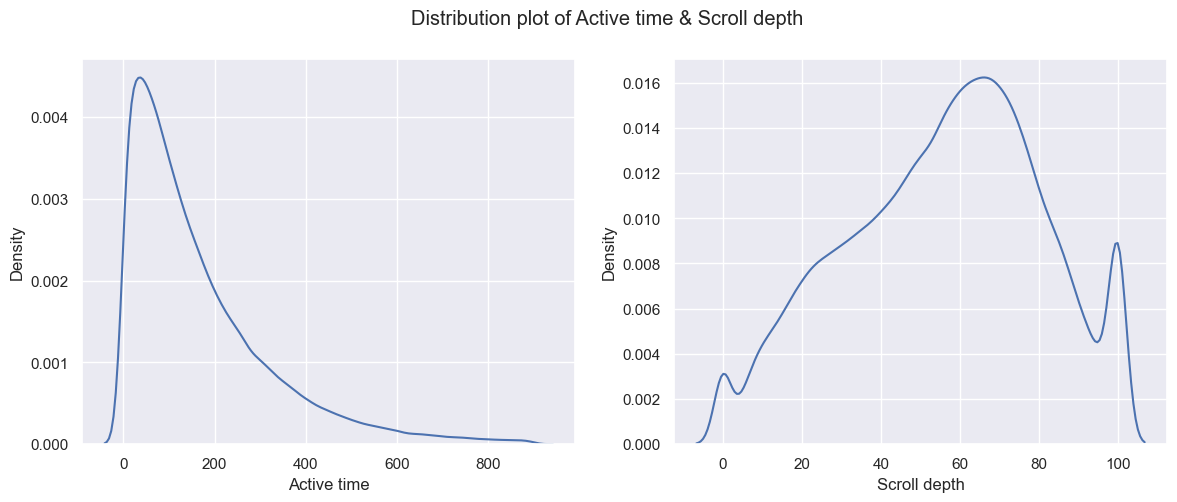

In [6]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=activity_query_data, x="avg_active_time")
sns.kdeplot(ax=axes[1], data=activity_query_data, x="avg_scroll_depth")
fig.suptitle("Distribution plot of Active time & Scroll depth")
axes[0].set_xlabel("Active time")
axes[1].set_xlabel("Scroll depth")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

Kadangi Active time ir Scroll depth dydžių pasiskirstymas yra nevienodas, o Active time atveju jis yra labai "skewed", todėl "vidutinei" reikšmei rasti naudosime ne vidurkį, o medianą.

In [7]:
rfv_df = activity_query_data.groupby("user_delfi_id").agg(
    frequency=("date", lambda x: x.nunique()),
    volume=("pageviews", "sum"),
    last_visit=("date", "max"),
    median_active_time=("avg_active_time", "median"),
    avg_scroll_depth=("avg_scroll_depth", "mean")
).reset_index()

In [8]:
latest_date = activity_query_data["date"].max().strftime("%Y-%m-%d")

# The latest data of activity.
anchor_date = pd.to_datetime(latest_date).date()
rfv_df["recency"] = (anchor_date - rfv_df["last_visit"]).dt.days

In [9]:
# Calculate RFV score.
rfv_df["rfv_score"] = (rfv_df["frequency"] * np.sqrt((rfv_df["volume"]))) / (rfv_df["recency"] + 1)
rfv_df["user_delfi_id"] = rfv_df["user_delfi_id"].astype("string")
rfv_df.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,avg_scroll_depth,recency,rfv_score
0,1735,19,21,2023-03-26,4.00,31.62,1,43.53
1,2140,44,81,2023-03-27,227.75,60.37,0,396.00
2,2320,43,83,2023-03-25,114.00,47.27,2,130.58
3,2872,27,41,2023-03-26,169.00,71.50,1,86.44
4,3069,56,201,2023-03-25,67.00,47.22,2,264.65


In [10]:
# User ID and User Delfi ID from Delfi internal database.
user_id_query = """
    SELECT id, delfi_id
    FROM paywall.users
    WHERE delfi_id IS NOT NULL
    """

user_id_data = pd.read_sql(user_id_query, dlf_paywall_db)
user_id_data = user_id_data.astype("string")
user_id_data.head()

,id,delfi_id
0,75757,5
1,2862,6
2,17038,7
3,76102,8
4,89277,9


In [11]:
rfv_df = rfv_df.merge(user_id_data, how="left", left_on="user_delfi_id", right_on="delfi_id").rename(columns={"id": "user_id"})
rfv_df.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,avg_scroll_depth,recency,rfv_score,user_id,delfi_id
0,1735,19,21,2023-03-26,4.00,31.62,1,43.53,4362,1735
1,2140,44,81,2023-03-27,227.75,60.37,0,396.00,14449,2140
2,2320,43,83,2023-03-25,114.00,47.27,2,130.58,5856,2320
3,2872,27,41,2023-03-26,169.00,71.50,1,86.44,56979,2872
4,3069,56,201,2023-03-25,67.00,47.22,2,264.65,56747,3069


In [12]:
# All users
all_users_query = """
    SELECT DISTINCT US.user_id, plan, renewal
    FROM user_subscriptions AS US
    LEFT JOIN subscriptions AS S
    ON US.subscription_id = S.id
    WHERE S.included_in_count = 1
    AND S.service_id IN (1, 3, 4, 9, 10)
    AND valid_till > "2023-01-24 23:59:59"
    AND S.sf_category = "Paid subscriptions"
    """

all_users = pd.read_sql(all_users_query, dlf_paywall_db)
all_users = all_users.astype("string")
all_users.head()

,user_id,plan,renewal
0,110,1,1
1,92,6,1
2,243,6,1
3,1796,6,1
4,1865,6,1


In [13]:
# Users who were active during whole period.
filtered_users_query = """
    SELECT P1.user_id, P1.plan, P1.renewal
    FROM (SELECT T.user_id, T.completion_timestamp, S.plan, US.renewal,
        ROW_NUMBER() OVER (PARTITION BY T.user_id ORDER BY T.completion_timestamp) AS row_num
        FROM paywall.transactions AS T
		LEFT JOIN paywall.user_subscriptions AS US
		ON T.user_id = US.user_id
		LEFT JOIN paywall.subscriptions AS S
		ON US.subscription_id = S.id
		WHERE US.service_id IN (1, 3, 4, 9, 10)
		AND S.included_in_count = 1
		AND T.completion_timestamp IS NOT NULL
		AND S.sf_category = "Paid subscriptions"
		AND US.valid_till > "%s 23:59:59") AS P1
    WHERE P1.row_num = 1
    AND P1.completion_timestamp < "2023-01-25 00:00:00"
    """ % latest_date

filtered_users = pd.read_sql(filtered_users_query, dlf_paywall_db)
filtered_users = filtered_users.astype("string")
filtered_users.head()

,user_id,plan,renewal
0,8,12,0
1,30,12,1
2,34,12,1
3,45,12,0
4,50,12,0


In [14]:
all_users = all_users.drop_duplicates(subset="user_id", keep=False)
filtered_users = filtered_users.drop_duplicates(subset="user_id", keep=False)

In [15]:
all_users_final = rfv_df.merge(all_users, on="user_id").drop(columns="delfi_id")
all_users_final = all_users_final.astype({"user_delfi_id": "string", "user_id": "string"})

filtered_users_final = rfv_df.merge(filtered_users, on="user_id").drop(columns="delfi_id")
filtered_users_final = filtered_users_final.astype({"user_delfi_id": "string", "user_id": "string"})

In [16]:
def transactions_dataframe(connector: object, users: list) -> pd.DataFrame:
    """Takes in DB connector, list IDs of users and returns dataframe with queried information about transactions from internal Delfi database.
    
    Keyword arguments:
    connector -- MySQL connector for connecting to internal Delfi database.
    list - list of required IDs of users.
    """

    cursor = connector.cursor()

    parameters_count =", ".join(list(map(lambda x: "%s", users)))
    
    transactions_query = """
        SELECT user_id, COUNT(T.id), SUM(sum)
        FROM paywall.transactions AS T
        LEFT JOIN paywall.subscriptions AS S
        ON T.subscription_id = S.id
        WHERE completion_timestamp IS NOT NULL
        AND S.service_id IN (1, 3, 4, 9, 10)
        AND sum > 0
        AND user_id IN (%s)
        GROUP BY user_id
        """
    transactions_query = transactions_query % parameters_count
        
    cursor.execute(transactions_query, users)

    user_id = []
    transactions_count = []
    amount = []

    for user, count, sum in cursor:
        user_id.append(user)
        transactions_count.append(count)
        amount.append(sum)
    
    cursor.close()
       
    transactions_data = pd.DataFrame({
        "user_id": user_id,
        "transactions_count": transactions_count,
        "total_amount": amount
    })

    transactions_data["user_id"] = transactions_data["user_id"].astype(str)
    
    return transactions_data

In [17]:
# Get information about transactions from Delfi internal DB.
all_users_ids = all_users_final["user_id"].astype(int).to_list()
filtered_users_ids = filtered_users_final["user_id"].astype(int).to_list()

all_users_transactions = transactions_dataframe(dlf_paywall_db, all_users_ids)
filtered_users_transactions = transactions_dataframe(dlf_paywall_db, filtered_users_ids)

In [18]:
all_users_final = all_users_final.merge(all_users_transactions, how="inner", on="user_id")
filtered_users_final = filtered_users_final.merge(filtered_users_transactions, how="inner", on="user_id")

In [19]:
# List of emails of users who gave consent for newsletters.
consent_emails = pd.read_csv("content_emails.txt", header=None, skipfooter=1).rename(columns={0: "email"}).drop_duplicates()

# Querying emails of users from internal Delfi database. 
user_email_query = """
    SELECT id, email
    FROM paywall.users
    WHERE email IS NOT NULL
    """

user_email_data = pd.read_sql(user_email_query, dlf_paywall_db)
user_email_data["id"] = user_email_data["id"].astype("str")
user_email_data = user_email_data.rename(columns={"id": "user_id"})


consent_users = consent_emails.merge(user_email_data, how="left", on="email")
consent_users["consent"] = "1"

all_users_final = all_users_final.merge(consent_users[["user_id", "consent"]], how="left", on="user_id").fillna(value={"consent": "0"})
filtered_users_final = filtered_users_final.merge(consent_users[["user_id", "consent"]], how="left", on="user_id").fillna(value={"consent": "0"})

In [20]:
print("All data samples:", len(all_users_final))
print("Cleaned data samples:", len(filtered_users_final))
print("Difference between all and cleaned data:", len(all_users_final) - len(filtered_users_final))

All data samples: 12758
Cleaned data samples: 11881
Difference between all and cleaned data: 877


# Part 2: Data visualization

## RFV score vs. Total amount spent & Count of transactiont

### All data

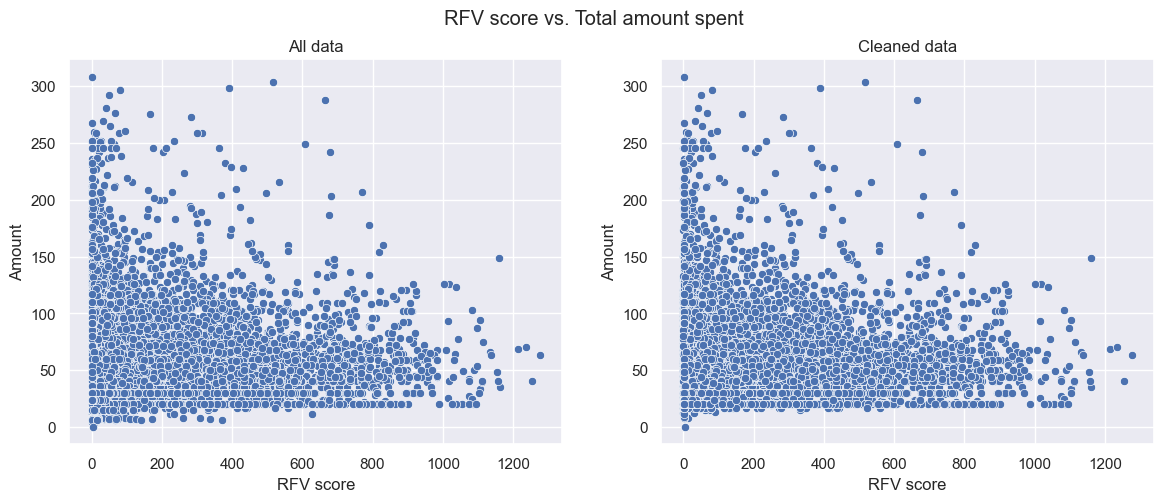

In [21]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final, x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=filtered_users_final, x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

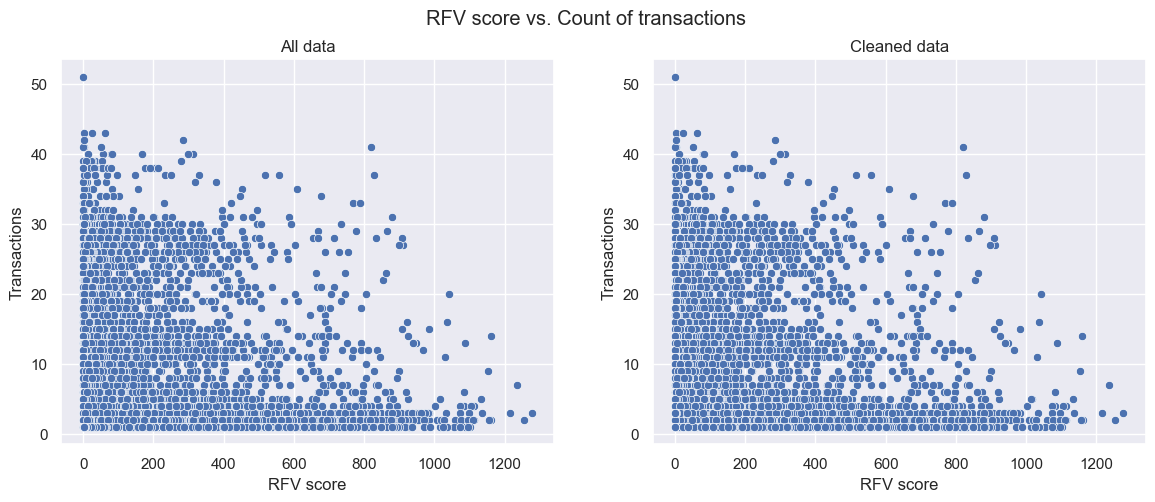

In [22]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final, x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=filtered_users_final, x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

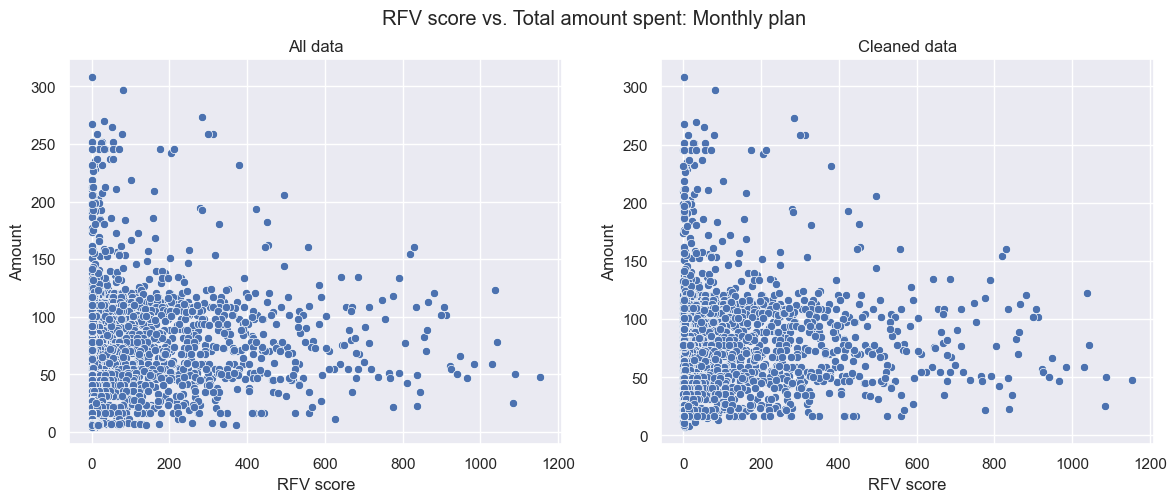

In [23]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final[all_users_final["plan"] == "1"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=filtered_users_final[filtered_users_final["plan"] == "1"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

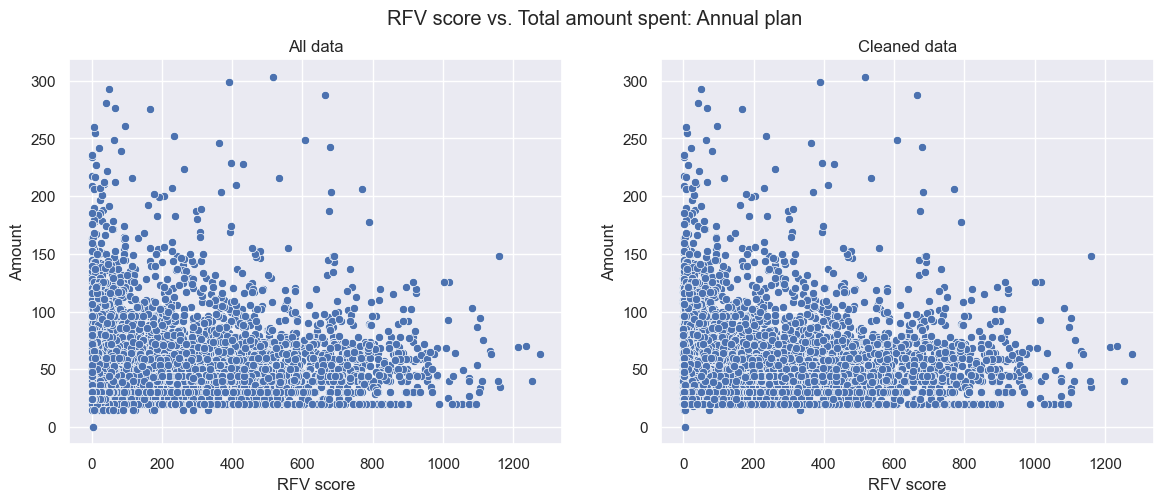

In [24]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final[all_users_final["plan"] == "12"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=filtered_users_final[filtered_users_final["plan"] == "12"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

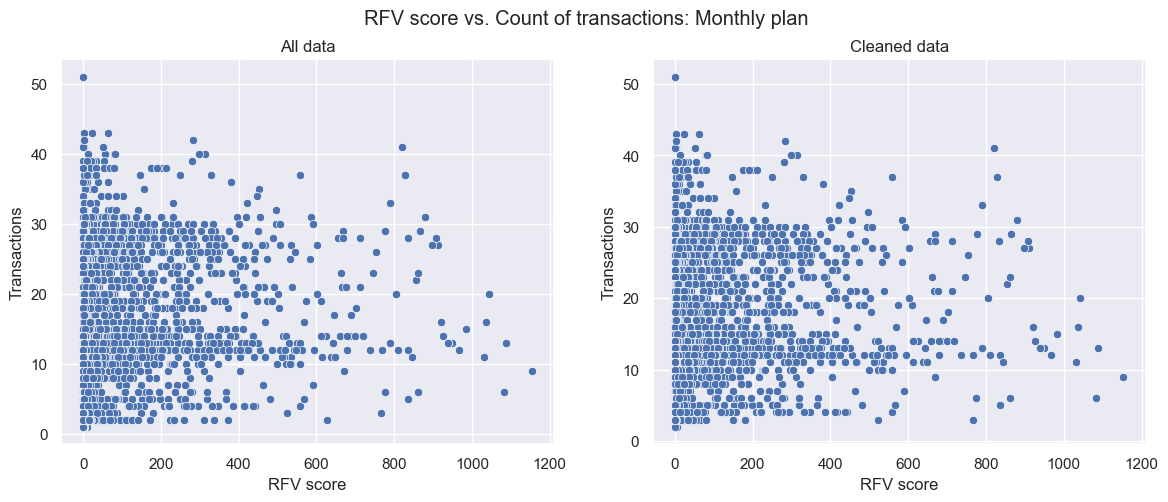

In [25]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final[all_users_final["plan"] == "1"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=filtered_users_final[filtered_users_final["plan"] == "1"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

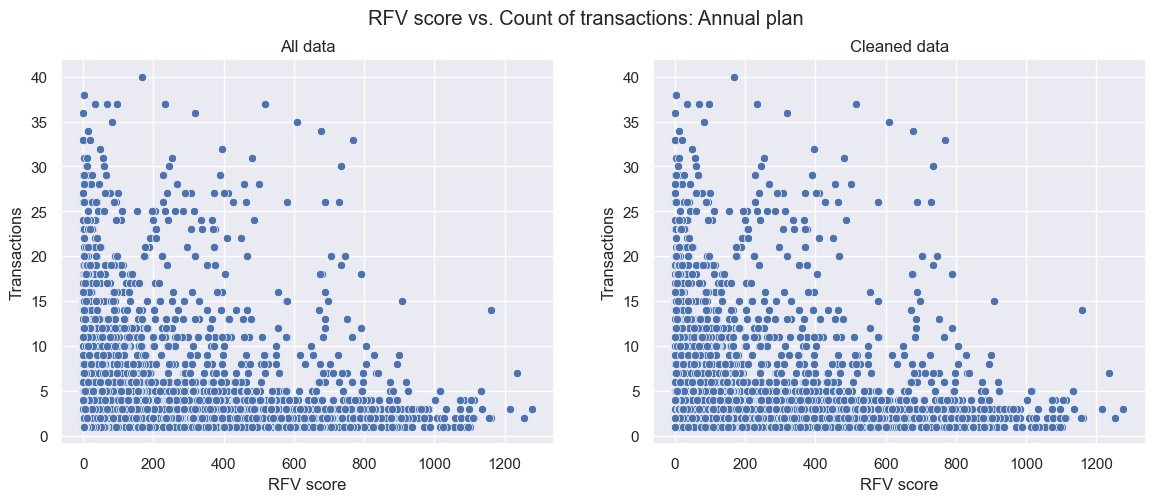

In [26]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final[all_users_final["plan"] == "12"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=filtered_users_final[filtered_users_final["plan"] == "12"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

Iš aukčiau esančių grafikų matosi, kad nėra jokios aiškios RFV priklausomybės tiek nuo transakcijų skaičiau, tiek nuo bendros išleistos sumos. 

### Transition between plans

Taip pat atskirai iš transakcijų kiekio grafikų matosi, kad yra nemažai taškų, kurių metinių prenumeratų transakcijų skaičius yra daugiau nei 4, kas reiškia, kad daugeliu atveju vartotojas keitėsi iš metinės prenumeratos į mėnesinę arba atvirkščiai. Tai šiek tiek komplikuoja vartotojų išskyrimą pagal planus, todėl sekančiu žingsiu eliminuosiu visus aktyvius vartotojus, kurie yra darę pakeitimą tarp planų.

In [27]:
transactions_count_query = """
    SELECT T.user_id, S.plan, COUNT(T.id) AS transactions_count, SUM(T.sum) AS total_amount
    FROM paywall.transactions AS T
    LEFT JOIN paywall.subscriptions AS S
    ON T.subscription_id = S.id
    WHERE T.completion_timestamp IS NOT NULL
    AND T.sum > 0
    AND S.service_id IN (1, 3, 4, 9, 10)
    GROUP BY T.user_id, S.plan
    HAVING S.plan IN (1, 12)
    """

transactions_count_data = pd.read_sql(transactions_count_query, dlf_paywall_db)
transactions_count_data = transactions_count_data.astype("string")
transactions_count_data.head()

,user_id,plan,transactions_count,total_amount
0,14,1,2,2.0
1,196,1,1,1.0
2,26,1,3,16.98
3,27,1,2,8.99
4,28,1,6,40.95


In [28]:
users_plans_count = transactions_count_data["user_id"].value_counts().reset_index().rename(columns={"index": "user_id", "user_id": "plans_count"})
users_one_plan = users_plans_count[users_plans_count["plans_count"] == 1]
users_one_plan["user_id"] = users_one_plan["user_id"].astype(str)

In [29]:
# Data of users with just one plan during their whole lifetime.
all_users_final_ONE = all_users_final.merge(users_one_plan, how="inner", on="user_id")
filtered_users_final_ONE = filtered_users_final.merge(users_one_plan, how="inner", on="user_id")

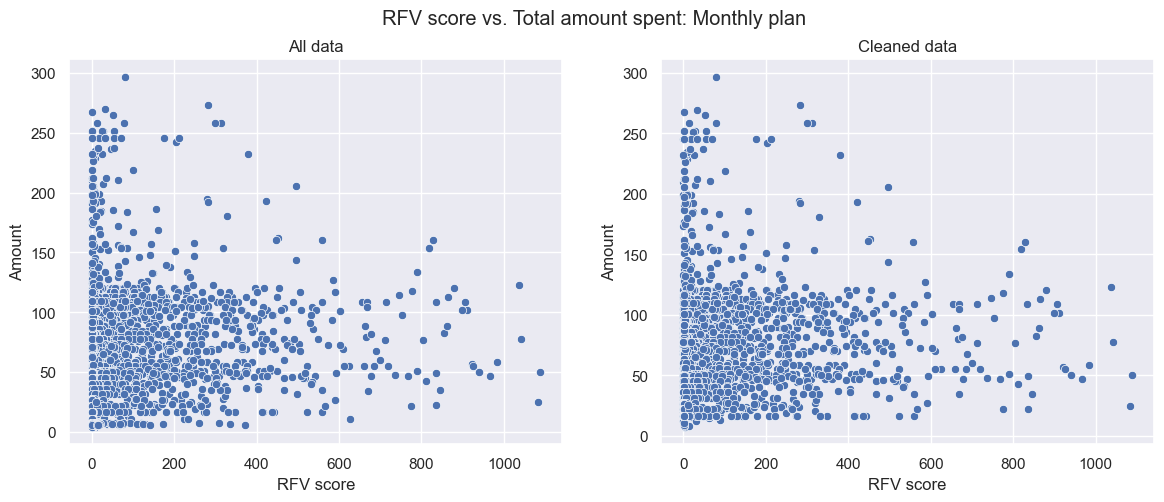

In [30]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "1"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "1"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

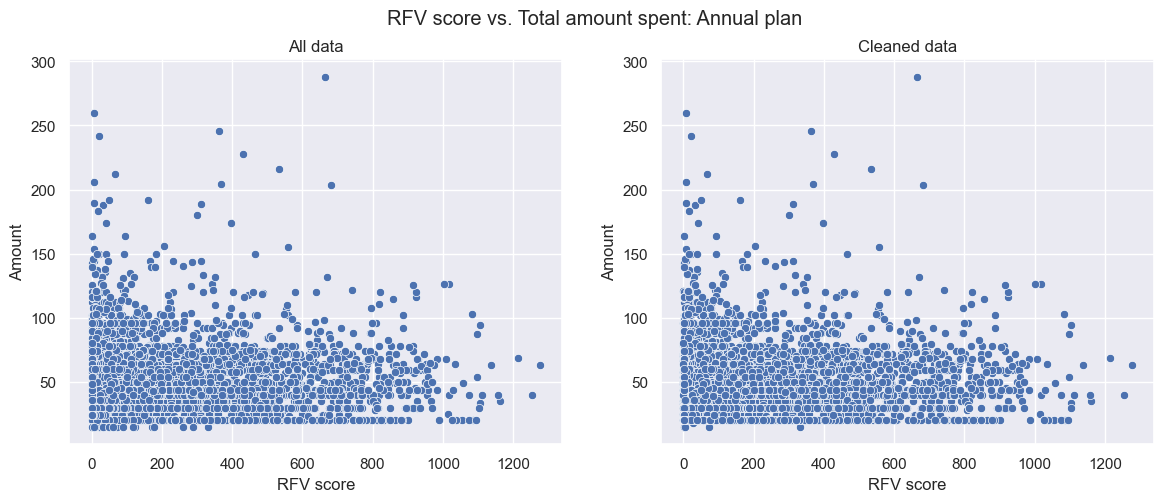

In [31]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "12"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "12"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

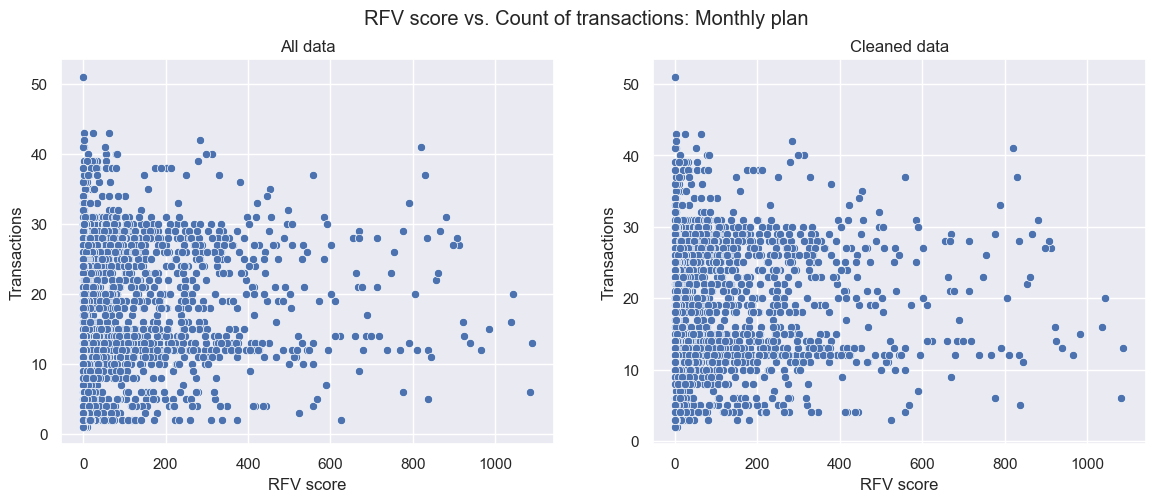

In [32]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "1"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "1"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

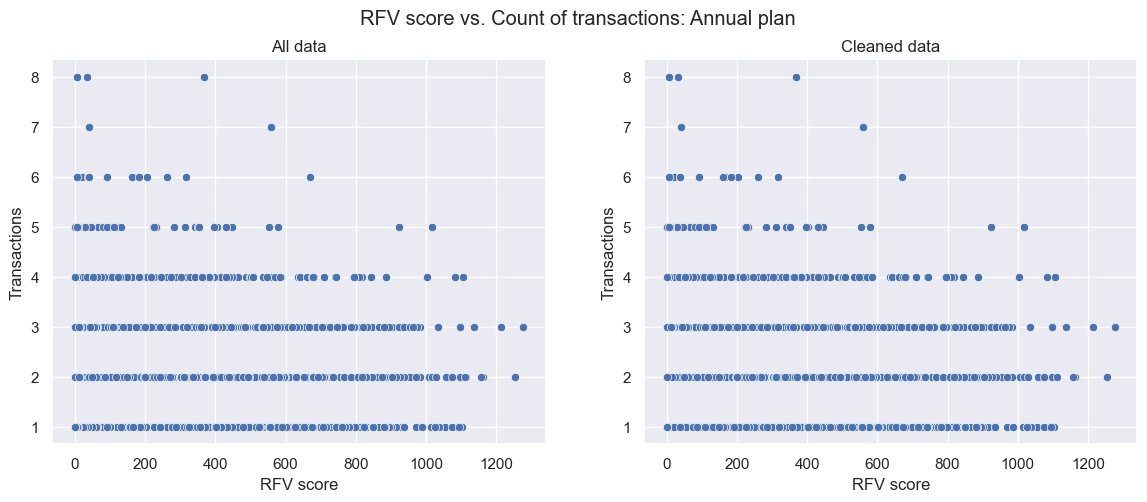

In [33]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "12"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "12"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

Nors chaosas duomenyse ir sumažėjo, kai buvo eliminuoti vartotojai, kurie per savo gyvavimo trukmę keitė planus, tačiau aiškios RFV priklausomybės taip ir neatsirado.

### Standard deviation

Išfiltruoti mėnesinių ir metinių planų RFV, kurie neviršyja vieno standartinio nuokrypio.

In [34]:
rfv_std_monthly_all = all_users_final_ONE[all_users_final_ONE["plan"] == "1"]["rfv_score"].std()
rfv_std_monthly_cleaned = filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "1"]["rfv_score"].std()

rfv_std1_monthly_all_df = all_users_final_ONE[(all_users_final_ONE["plan"] == "1") & (all_users_final_ONE["rfv_score"] < rfv_std_monthly_all)]
rfv_std1_monthly_cleaned_df = all_users_final_ONE[(all_users_final_ONE["plan"] == "1") & (all_users_final_ONE["rfv_score"] < rfv_std_monthly_cleaned)]

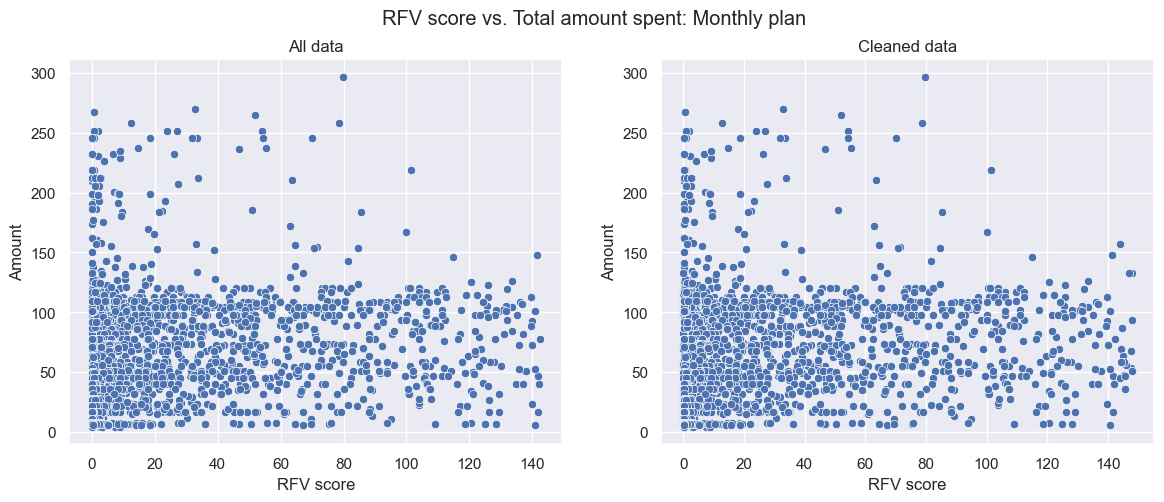

In [35]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_monthly_all_df[rfv_std1_monthly_all_df["plan"] == "1"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=rfv_std1_monthly_cleaned_df[rfv_std1_monthly_cleaned_df["plan"] == "1"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

In [36]:
rfv_std_annual_all = all_users_final_ONE[all_users_final_ONE["plan"] == "12"]["rfv_score"].std()
rfv_std_annual_cleaned = filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "12"]["rfv_score"].std()

rfv_std1_annual_all_df = all_users_final_ONE[(all_users_final_ONE["plan"] == "12") & (all_users_final_ONE["rfv_score"] < rfv_std_annual_all)]
rfv_std1_annual_cleaned_df = all_users_final_ONE[(all_users_final_ONE["plan"] == "12") & (all_users_final_ONE["rfv_score"] < rfv_std_annual_cleaned)]

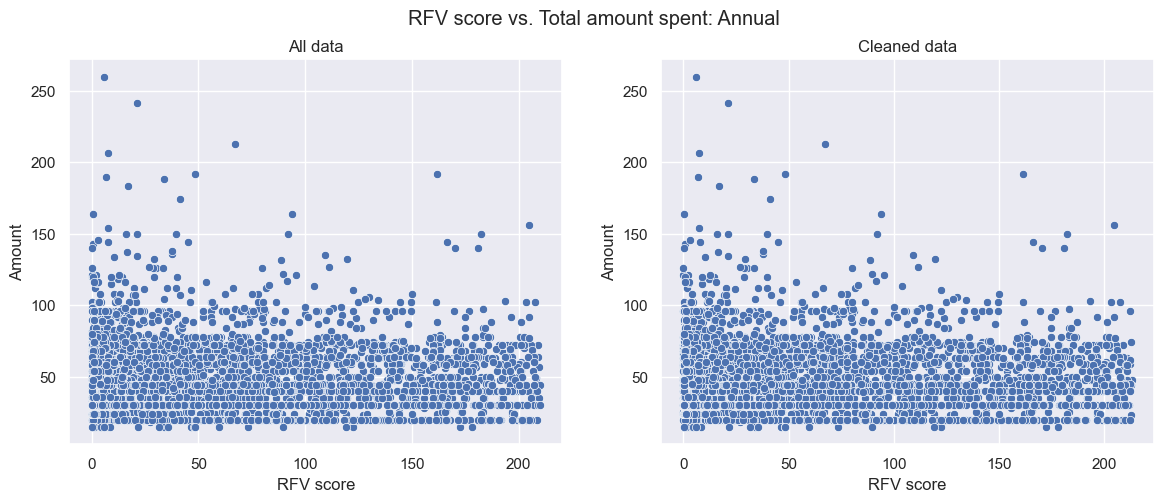

In [37]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_annual_all_df[rfv_std1_annual_all_df["plan"] == "12"], x="rfv_score", y="total_amount")
sns.scatterplot(ax=axes[1], data=rfv_std1_annual_cleaned_df[rfv_std1_annual_cleaned_df["plan"] == "12"], x="rfv_score", y="total_amount")
fig.suptitle("RFV score vs. Total amount spent: Annual")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Amount")
axes[1].set_ylabel("Amount");

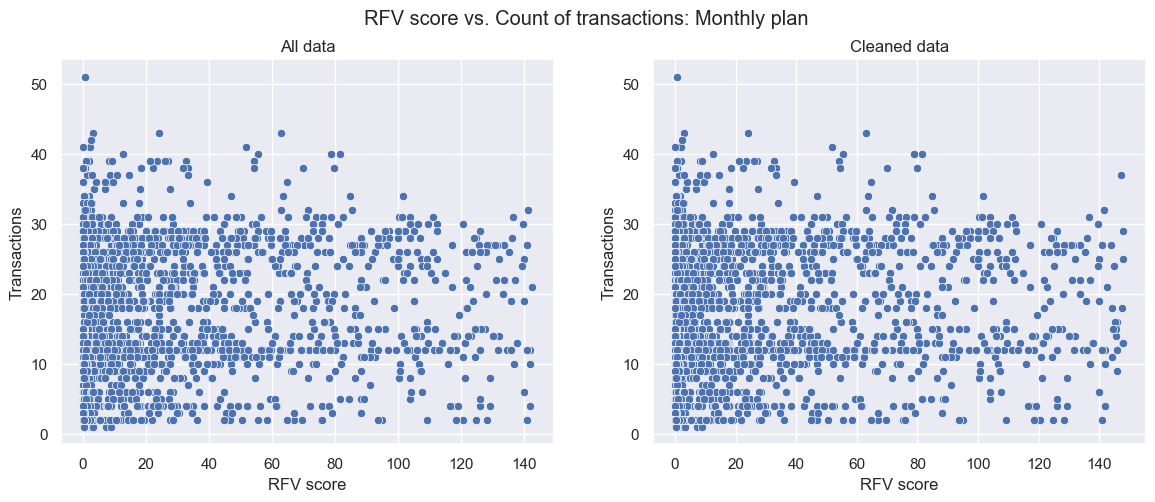

In [38]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_monthly_all_df[rfv_std1_monthly_all_df["plan"] == "1"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=rfv_std1_monthly_cleaned_df[rfv_std1_monthly_cleaned_df["plan"] == "1"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Count of transactions: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

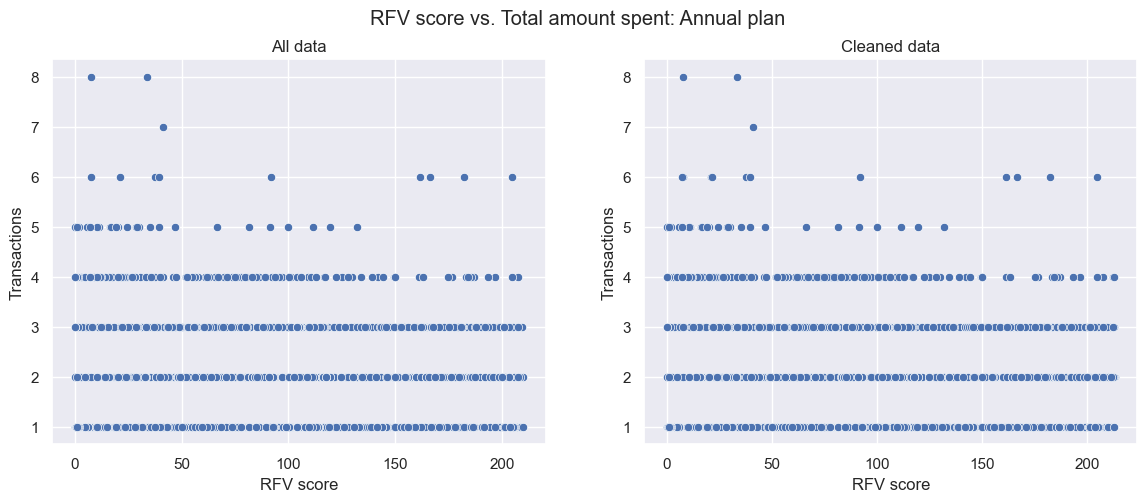

In [39]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.scatterplot(ax=axes[0], data=rfv_std1_annual_all_df[rfv_std1_annual_all_df["plan"] == "12"], x="rfv_score", y="transactions_count")
sns.scatterplot(ax=axes[1], data=rfv_std1_annual_cleaned_df[rfv_std1_annual_cleaned_df["plan"] == "12"], x="rfv_score", y="transactions_count")
fig.suptitle("RFV score vs. Total amount spent: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions");

## RFV score distribution by features

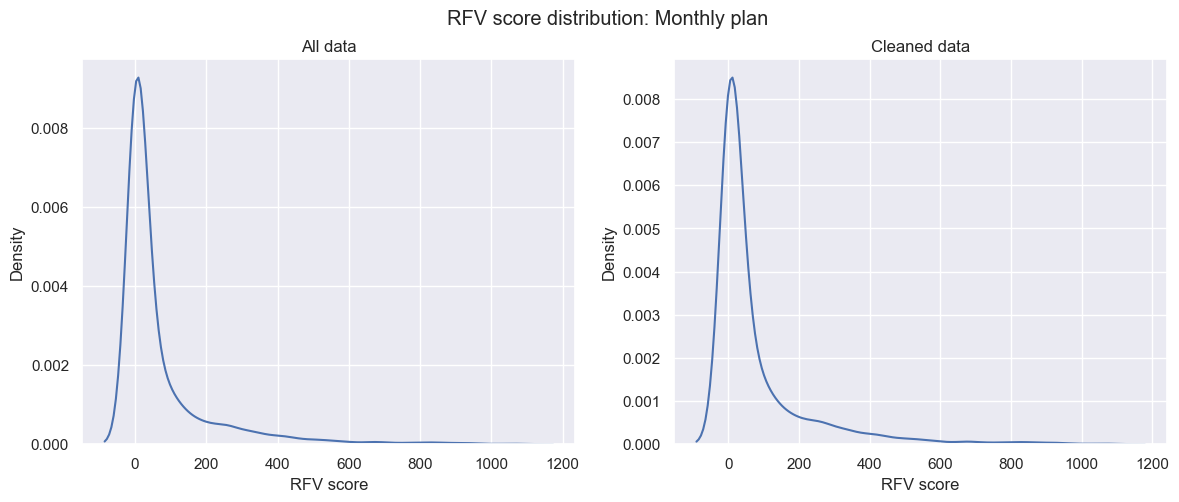

In [40]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "1"], x="rfv_score")
sns.kdeplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "1"], x="rfv_score")
fig.suptitle("RFV score distribution: Monthly plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

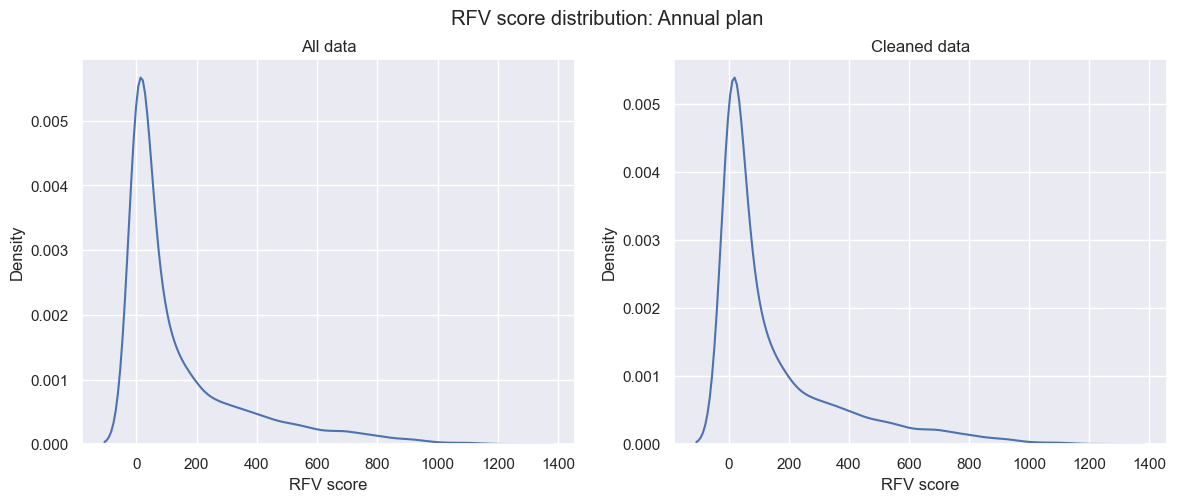

In [41]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=all_users_final_ONE[all_users_final_ONE["plan"] == "12"], x="rfv_score")
sns.kdeplot(ax=axes[1], data=filtered_users_final_ONE[filtered_users_final_ONE["plan"] == "12"], x="rfv_score")
fig.suptitle("RFV score distribution: Annual plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("RFV score")
axes[1].set_xlabel("RFV score")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

Iš grafikų matosi, kad RFV indeksas yra pasiskirstęs netolygiai, dėl to naudosiu ne vidurkį, o medianą.

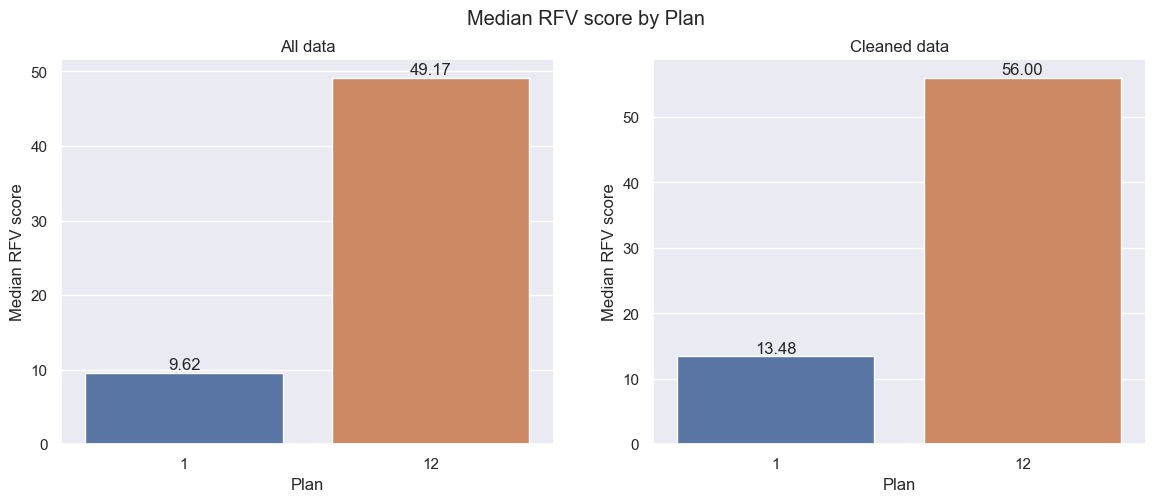

In [42]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.barplot(ax=axes[0], data=all_users_final_ONE[(all_users_final_ONE["plan"] == "1") | (all_users_final_ONE["plan"] == "12")].groupby("plan")["rfv_score"].median().reset_index(),
            x="plan", y="rfv_score")
sns.barplot(ax=axes[1], data=filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["rfv_score"].median().reset_index(),
            x="plan", y="rfv_score")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
fig.suptitle("Median RFV score by Plan")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("Plan")
axes[1].set_xlabel("Plan")
axes[0].set_ylabel("Median RFV score")
axes[1].set_ylabel("Median RFV score");

In [43]:
pd.DataFrame({
    "Users": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["user_id"].count(),
    "Share": (filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["user_id"].count() 
              / filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")]["user_id"].count() * 100),
    "RFV": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["rfv_score"].median(),
    "Frequency": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["frequency"].median(),
    "Recency": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["recency"].median(),
    "Volume": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["volume"].median(),
    "Active time": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["median_active_time"].median(),
    "Scroll depth": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["avg_scroll_depth"].median(),
    "Transactions": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["transactions_count"].median(),
    "Amount": filtered_users_final_ONE[(filtered_users_final_ONE["plan"] == "1") | (filtered_users_final_ONE["plan"] == "12")].groupby("plan")["total_amount"].median(),
}).set_axis(["Plan: Monthly", "Plan: Annual"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Plan: Monthly,2870,28.54,13.48,13.00,3.00,16.00,108.25,55.00,18.00,77.80
Plan: Annual,7187,71.46,56.00,22.00,1.00,33.00,115.75,55.50,2.00,43.99


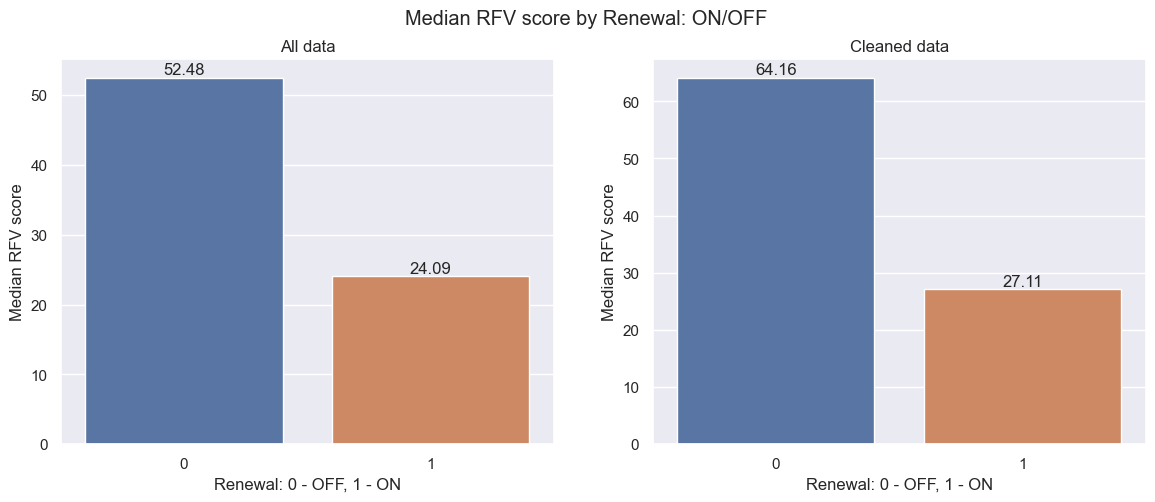

In [44]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.barplot(ax=axes[0], data=all_users_final.groupby("renewal")["rfv_score"].median().reset_index(), x="renewal", y="rfv_score")
sns.barplot(ax=axes[1], data=filtered_users_final.groupby("renewal")["rfv_score"].median().reset_index(), x="renewal", y="rfv_score")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
fig.suptitle("Median RFV score by Renewal: ON/OFF")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("Renewal: 0 - OFF, 1 - ON")
axes[1].set_xlabel("Renewal: 0 - OFF, 1 - ON")
axes[0].set_ylabel("Median RFV score")
axes[1].set_ylabel("Median RFV score");

In [45]:
pd.DataFrame({
    "Users": filtered_users_final.groupby("renewal")["user_id"].count(),
    "Share": filtered_users_final.groupby("renewal")["user_id"].count() / filtered_users_final["user_id"].count() * 100,
    "RFV": filtered_users_final.groupby("renewal")["rfv_score"].median(),
    "Frequency": filtered_users_final.groupby("renewal")["frequency"].median(),
    "Recency": filtered_users_final.groupby("renewal")["recency"].median(),
    "Volume": filtered_users_final.groupby("renewal")["volume"].median(),
    "Active time": filtered_users_final.groupby("renewal")["median_active_time"].median(),
    "Scroll depth": filtered_users_final.groupby("renewal")["avg_scroll_depth"].median(),
    "Transactions": filtered_users_final.groupby("renewal")["transactions_count"].median(),
    "Amount": filtered_users_final.groupby("renewal")["total_amount"].median(),
}).set_axis(["Renewal: OFF", "Renewal: ON"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Renewal: OFF,5590,47.05,64.16,24.00,1.00,36.00,116.12,55.52,2.00,43.99
Renewal: ON,6291,52.95,27.11,17.00,2.00,23.00,110.12,55.17,6.00,60.40


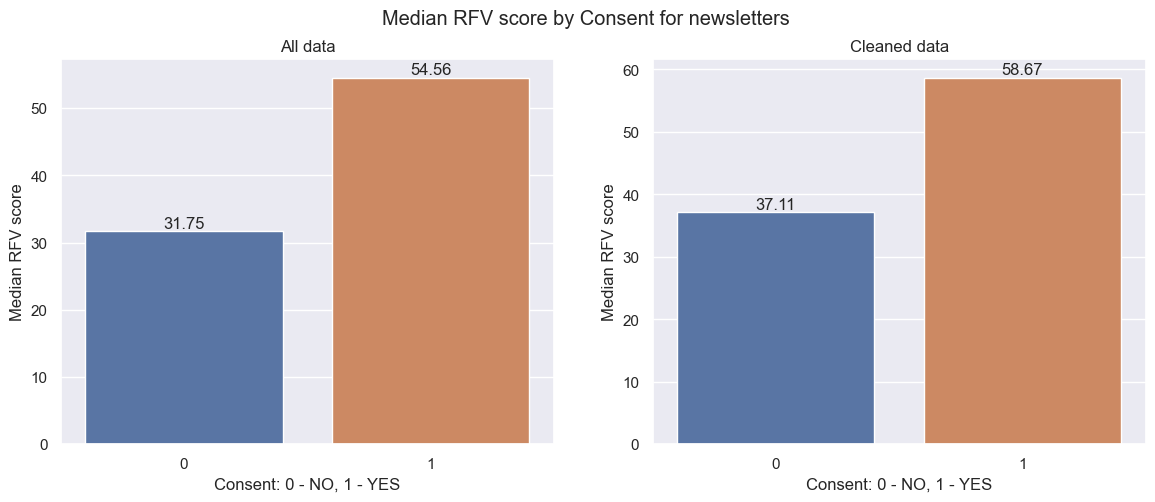

In [46]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.barplot(ax=axes[0], data=all_users_final.groupby("consent")["rfv_score"].median().reset_index(), x="consent", y="rfv_score")
sns.barplot(ax=axes[1], data=filtered_users_final.groupby("consent")["rfv_score"].median().reset_index(), x="consent", y="rfv_score")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
fig.suptitle("Median RFV score by Consent for newsletters")
axes[0].set_title("All data")
axes[1].set_title("Cleaned data")
axes[0].set_xlabel("Consent: 0 - NO, 1 - YES")
axes[1].set_xlabel("Consent: 0 - NO, 1 - YES")
axes[0].set_ylabel("Median RFV score")
axes[1].set_ylabel("Median RFV score");

In [47]:
pd.DataFrame({
    "Users": filtered_users_final.groupby("consent")["user_id"].count(),
    "Share": filtered_users_final.groupby("consent")["user_id"].count() / filtered_users_final["user_id"].count() * 100,
    "RFV": filtered_users_final.groupby("consent")["rfv_score"].median(),
    "Frequency": filtered_users_final.groupby("consent")["frequency"].median(),
    "Recency": filtered_users_final.groupby("consent")["recency"].median(),
    "Volume": filtered_users_final.groupby("consent")["volume"].median(),
    "Active time": filtered_users_final.groupby("consent")["median_active_time"].median(),
    "Scroll depth": filtered_users_final.groupby("consent")["avg_scroll_depth"].median(),
    "Transactions": filtered_users_final.groupby("consent")["transactions_count"].median(),
    "Amount": filtered_users_final.groupby("consent")["total_amount"].median(),
}).set_axis(["Consent: NO", "Consent: YES"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Consent: NO,9033,76.03,37.11,19.00,2.00,27.00,111.00,55.13,3.00,49.98
Consent: YES,2848,23.97,58.67,23.00,1.00,36.00,119.75,55.98,3.00,59.96


# Part 3: Syntetic RFV

In [48]:
recency_threshold = 6

syntetic_rfv_data = filtered_users_final.copy()
syntetic_rfv_data["recency_threshold_user"] = np.where(filtered_users_final["recency"] <= recency_threshold, "fans", "sleepers")
syntetic_rfv_data.head()

,user_delfi_id,frequency,volume,last_visit,median_active_time,avg_scroll_depth,recency,rfv_score,user_id,plan,renewal,transactions_count,total_amount,consent,recency_threshold_user
0,2140,44,81,2023-03-27,227.75,60.37,0,396.00,14449,12,0,2,48.00,1,fans
1,2320,43,83,2023-03-25,114.00,47.27,2,130.58,5856,1,1,14,92.88,0,fans
2,2872,27,41,2023-03-26,169.00,71.50,1,86.44,56979,1,1,27,101.75,0,fans
3,3069,56,201,2023-03-25,67.00,47.22,2,264.65,56747,12,0,3,73.98,0,fans
4,11878,19,24,2023-03-15,133.50,71.82,12,7.16,99419,12,1,2,40.00,1,sleepers


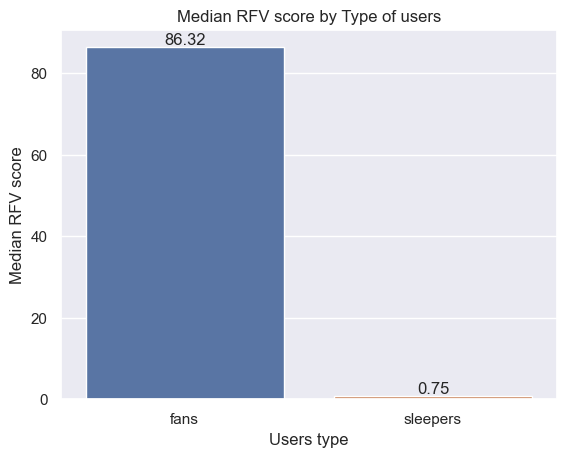

In [49]:
ax = sns.barplot(data=syntetic_rfv_data.groupby("recency_threshold_user")["rfv_score"].median().reset_index(), x="recency_threshold_user", y="rfv_score")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_title("Median RFV score by Type of users")
ax.set_xlabel("Users type")
ax.set_ylabel("Median RFV score");

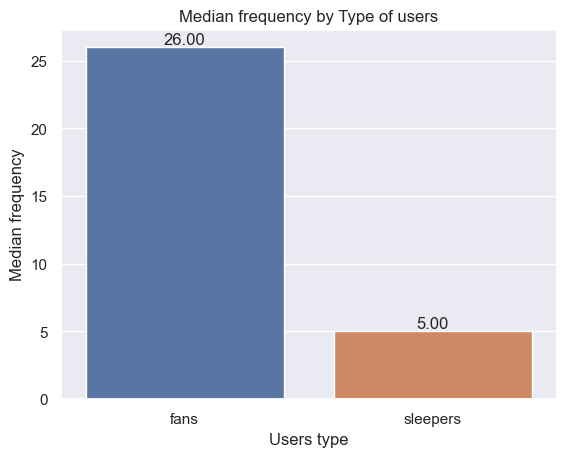

In [50]:
ax = sns.barplot(data=syntetic_rfv_data.groupby("recency_threshold_user")["frequency"].median().reset_index(), x="recency_threshold_user", y="frequency")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_title("Median frequency by Type of users")
ax.set_xlabel("Users type")
ax.set_ylabel("Median frequency");

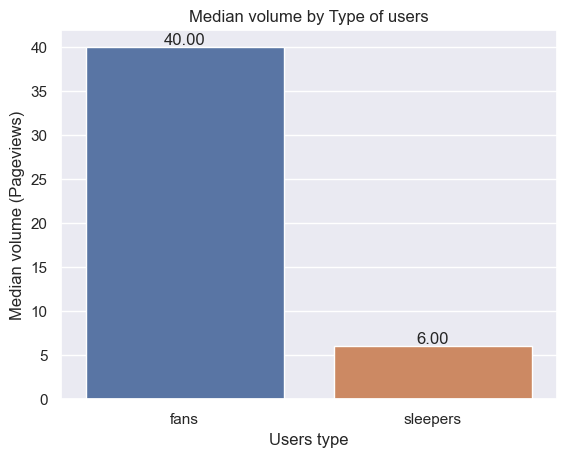

In [51]:
ax = sns.barplot(data=syntetic_rfv_data.groupby("recency_threshold_user")["volume"].median().reset_index(), x="recency_threshold_user", y="volume")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_title("Median volume by Type of users")
ax.set_xlabel("Users type")
ax.set_ylabel("Median volume (Pageviews)");

In [52]:
pd.DataFrame({
    "Users": syntetic_rfv_data.groupby("recency_threshold_user")["user_id"].count(),
    "Share": syntetic_rfv_data.groupby("recency_threshold_user")["user_id"].count() / syntetic_rfv_data["user_id"].count() * 100,
    "RFV score": syntetic_rfv_data.groupby("recency_threshold_user")["rfv_score"].median(),
    "Frequency": syntetic_rfv_data.groupby("recency_threshold_user")["frequency"].median(),
    "Recency": syntetic_rfv_data.groupby("recency_threshold_user")["recency"].median(),
    "Volume": syntetic_rfv_data.groupby("recency_threshold_user")["volume"].median()
}).set_axis(["Fans: Recency equal or below 6", "Sleepers: Recency above 6"], axis="index")

,Users,Share,RFV score,Frequency,Recency,Volume
Fans: Recency equal or below 6,9054,76.21,86.32,26.00,1.00,40.00
Sleepers: Recency above 6,2827,23.79,0.75,5.00,15.00,6.00


Kadangi duomeys nerodė jokios aiškios RFV rodiklio priklausomybės nuo įvairių apie vartotojus turimų charakteristikų, todėl buvo nuspręsta išskirti vartotojus į dvi grupes. Pirma grupė - tie vartotojai, kurie paskutinį kartą lankėsi prieš 6 dienas ir anksčiau, o antra grupė - tie, kurie paskutinį kartą lankėsi vėliau nei prieš 6 dienas. Lentelėje aukščiau matosi, kaip skiriasi RFV rodiklio pagrindinių sudedamųjų dalių vertės tarp grupių, todėl laikydami, kad nustatytas 6 dienų skaičius yra ribinis slenkstis, galime iš duomenų nusistatyti ribinius dažnį bei skaitytų puslapių kiekį ir taip apsiskaičiuoti ribinį RFV rodiklį.

In [53]:
frequency_threshold = syntetic_rfv_data[syntetic_rfv_data["recency"] == recency_threshold]["frequency"].median()
volume_threshold = syntetic_rfv_data[syntetic_rfv_data["recency"] == recency_threshold]["volume"].median()
print("Threshold of Frequency:", frequency_threshold)
print("Threshold of Volume:", volume_threshold)

Threshold of Frequency: 13.0
Threshold of Volume: 16.0


In [55]:
syntetic_rfv_score = (frequency_threshold * np.sqrt((volume_threshold))) / (recency_threshold + 1)
print("Threshold of RFV score:", syntetic_rfv_score)
print("Duration of period (Days):", activity_query_data["date"].nunique())

Threshold of RFV score: 7.428571428571429
Duration of period (Days): 62


Pagal apskačiuotą RFV rodiklį galime sakyti, kad įsitraukę vartotojai yra tie, kurie Delfi Plius svetainę paskutinį kartą aplankė ne seniau kaip prieš 7 dienas bei per analizuojamą laikotarpį skaitė ne mažiau kaip 9 straipsnius ir lankėsi ne rečiau kaip 7 kartus.